# 分档订正 CLI 批量调度（业务场景）

模拟真实调用：先裁到业务子域，再用封装 CLI `DscRedistributeCascadeCli` 做 `20,5,1` 订正。

1. **子域**：101–123°E、20–38°N。裁剪只 `isel`，不重网格。
2. **调度**：每个时次一次 CLI 调用，写出最终 1 km 订正场。
3. **检验**：只比订正前 / 订正后与实况的 Bias、RMSE，不算中间档。
4. **作图**：订正前、订正后、实况（第 1 个时次）。

**本窗口**：2026-07-27–28。小雨清空取业务常用值 `0.2`。

## 1. 准备

In [2]:
from __future__ import annotations

import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import meteva_base as meb

PKG = Path("..").resolve()
sys.path[:0] = [str(PKG.parent), str(PKG)]

from orographic_precipitation_downscaling.cli.redistribute_cascade_cli import (
    DscRedistributeCascadeCli,
)

DATA = PKG / "resource" / "data"
OBS_ROOT = PKG / "resource" / "CMPAS_APCP"
OUT = DATA / "output"

OROG_MODEL_SRC = PKG / "resource" / "ancil" / "EC_D1D_orography_20km.nc"
OROG_1KM_SRC = PKG / "resource" / "ancil" / "HGT_M_1KM_CHINA.nc"

CASE_INITS = ("2026072700", "2026072800")
STAGES = "20,5,1"
ZERO_BELOW = 0.2

# 裁剪后的输入与 CLI 输出，和源数据分开
CROP = OUT / "crop_101_123E_20_38N"
CORR = OUT / "corr_cascade_region"
FIG_DIR = OUT / "figs" / "cli_cascade_region"
VER_DIR = OUT / "verify"


def nc_index(root: Path) -> dict:
    """目录里所有 .nc → {时次标签: 路径}。"""
    files = meb.path_tools.get_path_list_in_dir(str(root))
    return {Path(p).stem: p for p in files if str(p).endswith(".nc")}


def ensure_units(da, fallback: str):
    u = str(da.attrs.get("units") or "").strip()
    if not u:
        da.attrs["units"] = fallback
    if da.attrs.get("units") == "m s**-1":
        da.attrs["units"] = "m s-1"
    return da


def write_nc(da, path: Path, name: str | None = None):
    path.parent.mkdir(parents=True, exist_ok=True)
    var = name or da.name or "data"
    out = da.copy()
    out.name = var
    out.to_dataset(name=var).to_netcdf(path, mode="w")
    return str(path)


tmp_ix = nc_index(DATA / "TMP")
rh_ix = nc_index(DATA / "RH")
pres_ix = nc_index(DATA / "PRES")
u_ix = nc_index(DATA / "UGRD")
v_ix = nc_index(DATA / "VGRD")

apcp_list = meb.path_tools.get_path_list_in_dir(str(PKG / "resource" / "EC" / "APCP01"))
apcp_list = sorted(
    p
    for p in apcp_list
    if str(p).endswith(".nc")
    and Path(p).stem in tmp_ix
    and Path(p).stem.split(".", 1)[0] in CASE_INITS
)

print("n forecasts", len(apcp_list))
print("example", apcp_list[0] if apcp_list else None)
print("crop dir", CROP)
print("corr dir", CORR)

n forecasts 14
example D:\workspace\test\00temp\orographic_precipitation_downscaling\resource\EC\APCP01\2026\20260727\NC\2026072700.003.nc
crop dir D:\workspace\test\00temp\orographic_precipitation_downscaling\resource\data\output\crop_101_123E_20_38N
corr dir D:\workspace\test\00temp\orographic_precipitation_downscaling\resource\data\output\corr_cascade_region


## 2. 经纬裁剪（与调度分开）

只按闭区间裁剪：`101–123°E`、`20–38°N`。地形裁一次，要素与降水按时次裁到 `output/crop_101_123E_20_38N/`。

In [3]:
LON0, LON1 = 101.0, 123.0
LAT0, LAT1 = 20.0, 38.0
RUN_CROP = True  # False 且裁剪结果已存在时跳过


def crop_lonlat(da, lon0=LON0, lon1=LON1, lat0=LAT0, lat1=LAT1):
    """按经纬闭区间裁剪；只 isel，不插值、不改保留格点数值。"""
    lat = np.asarray(da.lat.values)
    lon = np.asarray(da.lon.values)
    lat_sel = (lat >= lat0) & (lat <= lat1)
    lon_sel = (lon >= lon0) & (lon <= lon1)
    if not np.any(lat_sel) or not np.any(lon_sel):
        raise RuntimeError(
            f"裁剪后无格点: lon[{lon0},{lon1}] lat[{lat0},{lat1}] "
            f"data lon[{lon.min()},{lon.max()}] lat[{lat.min()},{lat.max()}]"
        )
    return da.isel(lat=lat_sel, lon=lon_sel)


OROG_MODEL = CROP / "ancil" / "EC_D1D_orography_20km.nc"
OROG_1KM = CROP / "ancil" / "HGT_M_1KM_CHINA.nc"

if RUN_CROP or not OROG_MODEL.exists() or not OROG_1KM.exists():
    orog_model = crop_lonlat(ensure_units(meb.read_griddata_from_nc(str(OROG_MODEL_SRC)), "m"))
    orog_1km = crop_lonlat(ensure_units(meb.read_griddata_from_nc(str(OROG_1KM_SRC)), "m"))
    write_nc(orog_model, OROG_MODEL, "orography")
    write_nc(orog_1km, OROG_1KM, "orography")
    print("cropped orography", OROG_MODEL.name, orog_model.sizes, "|", OROG_1KM.name, orog_1km.sizes)
else:
    orog_1km = ensure_units(meb.read_griddata_from_nc(str(OROG_1KM)), "m")
    print("reuse cropped orography", OROG_1KM)

grid1km = meb.get_grid_of_data(orog_1km)

field_specs = (
    ("TMP", tmp_ix, "degC"),
    ("RH", rh_ix, "%"),
    ("PRES", pres_ix, "Pa"),
    ("UGRD", u_ix, "m s-1"),
    ("VGRD", v_ix, "m s-1"),
)

cropped_index = {name: {} for name, _, _ in field_specs}
cropped_index["APCP01"] = {}

for apcp in apcp_list:
    tag = Path(apcp).stem
    apcp_out = CROP / "APCP01" / f"{tag}.nc"
    need = RUN_CROP or not apcp_out.exists()
    for name, _, _ in field_specs:
        if not (CROP / name / f"{tag}.nc").exists():
            need = True
            break
    if need:
        precip = crop_lonlat(ensure_units(meb.read_griddata_from_nc(apcp), "mm h-1"))
        write_nc(precip, apcp_out, precip.name or "precipitation_rate")
        for name, src_ix, units in field_specs:
            da = crop_lonlat(ensure_units(meb.read_griddata_from_nc(src_ix[tag]), units))
            write_nc(da, CROP / name / f"{tag}.nc", da.name or name.lower())
    cropped_index["APCP01"][tag] = str(apcp_out)
    for name, _, _ in field_specs:
        cropped_index[name][tag] = str(CROP / name / f"{tag}.nc")

print("cropped forecasts", len(cropped_index["APCP01"]))
print("domain", LON0, LON1, LAT0, LAT1)

cropped orography EC_D1D_orography_20km.nc Frozen({'member': 1, 'level': 1, 'time': 1, 'dtime': 1, 'lat': 91, 'lon': 111}) | HGT_M_1KM_CHINA.nc Frozen({'member': 1, 'level': 1, 'time': 1, 'dtime': 1, 'lat': 1801, 'lon': 2201})
cropped forecasts 14
domain 101.0 123.0 20.0 38.0


## 3. CLI 批量调度

每个时次调用一次 `DscRedistributeCascadeCli.call`，尺度 `20,5,1`，结果写到 `output/corr_cascade_region/`。

In [4]:
RUN_CASCADE = True  # False 且订正场已存在时跳过

CORR.mkdir(parents=True, exist_ok=True)

for tag, precip_path in cropped_index["APCP01"].items():
    corr_out = CORR / f"{tag}.nc"
    if not RUN_CASCADE and corr_out.exists():
        continue
    code = DscRedistributeCascadeCli.call(
        precip_path=precip_path,
        temperature_path=cropped_index["TMP"][tag],
        humidity_path=cropped_index["RH"][tag],
        pressure_path=cropped_index["PRES"][tag],
        uwind_path=cropped_index["UGRD"][tag],
        vwind_path=cropped_index["VGRD"][tag],
        orography_model_path=str(OROG_MODEL),
        orography_target_path=str(OROG_1KM),
        stages=STAGES,
        zero_below=ZERO_BELOW,
        output_path=str(corr_out),
    )
    if code != 0:
        raise RuntimeError(f"CLI 订正失败: {tag} code={code}")
    print("done", tag, "->", corr_out.name)

print("cascade outputs", len(list(CORR.glob("*.nc"))))

done 2026072700.003 -> 2026072700.003.nc
done 2026072700.006 -> 2026072700.006.nc
done 2026072700.009 -> 2026072700.009.nc
done 2026072700.012 -> 2026072700.012.nc
done 2026072700.015 -> 2026072700.015.nc
done 2026072700.018 -> 2026072700.018.nc
done 2026072700.021 -> 2026072700.021.nc
done 2026072800.003 -> 2026072800.003.nc
done 2026072800.006 -> 2026072800.006.nc
done 2026072800.009 -> 2026072800.009.nc
done 2026072800.012 -> 2026072800.012.nc
done 2026072800.015 -> 2026072800.015.nc
done 2026072800.018 -> 2026072800.018.nc
done 2026072800.021 -> 2026072800.021.nc
cascade outputs 14


## 4. 订正前 / 订正后 Bias、RMSE

- **订正前**：裁剪后的原始降水，线性插到 1 km 子域网格。
- **订正后**：CLI 输出的最终场。
- **实况**：有效世界时对应北京时终点及前两小时，三小时平均后插到同一网格。
- 不算中间档。ΔRMSE = 订正后 − 订正前（负值表示变好）。

In [5]:
def obs_3h_mean(valid_utc: datetime, grid):
    """有效世界时对应的北京时终点，取前 3 个整点实况平均，并插到目标网格。"""
    bjt_end = valid_utc + timedelta(hours=8)
    hours = [bjt_end - timedelta(hours=2), bjt_end - timedelta(hours=1), bjt_end]
    acc = None
    last = None
    for bjt in hours:
        path = OBS_ROOT / f"{bjt:%Y}" / f"{bjt:%Y%m%d}" / f"BJT_{bjt:%y%m%d%H}.000.nc"
        if not path.exists():
            raise FileNotFoundError(path)
        raw = crop_lonlat(meb.read_griddata_from_nc(str(path)))
        da = meb.interp_gg_linear(raw, grid, outer_value=np.nan)
        values = np.asarray(da.values, dtype=np.float64)
        acc = values if acc is None else acc + values
        last = da
    out = last.copy(data=(acc / 3.0).astype(np.float32))
    out.attrs["units"] = "mm h-1"
    out.name = "cmpas_3h_mean"
    return out


def _bias_rmse(pred, obs):
    mask = np.isfinite(pred) & np.isfinite(obs) & (np.abs(pred) < 1e10) & (np.abs(obs) < 1e10)
    if not np.any(mask):
        return float("nan"), float("nan"), 0
    diff = pred[mask] - obs[mask]
    return float(np.mean(diff)), float(np.sqrt(np.mean(diff**2))), int(mask.sum())


rows = []
sample = None
for tag, precip_path in cropped_index["APCP01"].items():
    init_s, lead_s = tag.split(".")
    init = datetime.strptime(init_s, "%Y%m%d%H")
    valid = init + timedelta(hours=int(lead_s))

    precip = ensure_units(meb.read_griddata_from_nc(precip_path), "mm h-1")
    before = meb.interp_gg_linear(precip, grid1km, outer_value=np.nan)
    before.attrs["units"] = "mm h-1"
    before.name = "precipitation_rate"
    after = ensure_units(meb.read_griddata_from_nc(str(CORR / f"{tag}.nc")), "mm h-1")
    obs = obs_3h_mean(valid, grid1km)

    bias0, rmse0, n = _bias_rmse(
        np.asarray(before.values, dtype=float).ravel(),
        np.asarray(obs.values, dtype=float).ravel(),
    )
    bias1, rmse1, _ = _bias_rmse(
        np.asarray(after.values, dtype=float).ravel(),
        np.asarray(obs.values, dtype=float).ravel(),
    )
    rows.append(
        {
            "tag": tag,
            "valid_utc": valid.strftime("%Y%m%d%H"),
            "bjt_end": (valid + timedelta(hours=8)).strftime("%Y%m%d%H"),
            "bias_before": bias0,
            "rmse_before": rmse0,
            "bias_after": bias1,
            "rmse_after": rmse1,
            "delta_rmse": rmse1 - rmse0,
            "n": n,
        }
    )
    print(
        f"{tag}  before bias={bias0:.3f} rmse={rmse0:.3f} | "
        f"after bias={bias1:.3f} rmse={rmse1:.3f} | "
        f"Δrmse={rmse1 - rmse0:+.3f} mm/h"
    )
    if sample is None:
        sample = {"tag": tag, "before": before, "after": after, "obs": obs}

hourly = pd.DataFrame(rows)
VER_DIR.mkdir(parents=True, exist_ok=True)
hourly_path = VER_DIR / "redistribute_cascade_cli_hourly.csv"
hourly.to_csv(hourly_path, index=False)
print(
    f"mean  before bias={hourly.bias_before.mean():.3f} rmse={hourly.rmse_before.mean():.3f} | "
    f"after bias={hourly.bias_after.mean():.3f} rmse={hourly.rmse_after.mean():.3f} | "
    f"Δrmse={hourly.delta_rmse.mean():+.3f} mm/h"
)
print("table", hourly_path)

2026072700.003  before bias=0.117 rmse=1.064 | after bias=0.089 rmse=1.057 | Δrmse=-0.007 mm/h
2026072700.006  before bias=0.201 rmse=1.106 | after bias=0.176 rmse=1.092 | Δrmse=-0.014 mm/h
2026072700.009  before bias=0.004 rmse=2.099 | after bias=-0.018 rmse=2.099 | Δrmse=-0.001 mm/h
2026072700.012  before bias=-0.171 rmse=2.065 | after bias=-0.196 rmse=2.071 | Δrmse=+0.006 mm/h
2026072700.015  before bias=-0.078 rmse=1.386 | after bias=-0.096 rmse=1.386 | Δrmse=+0.000 mm/h
2026072700.018  before bias=0.086 rmse=1.301 | after bias=0.070 rmse=1.292 | Δrmse=-0.009 mm/h
2026072700.021  before bias=0.003 rmse=1.899 | after bias=-0.015 rmse=1.899 | Δrmse=+0.000 mm/h
2026072800.003  before bias=0.032 rmse=1.343 | after bias=0.001 rmse=1.332 | Δrmse=-0.011 mm/h
2026072800.006  before bias=0.171 rmse=1.387 | after bias=0.142 rmse=1.371 | Δrmse=-0.016 mm/h
2026072800.009  before bias=0.140 rmse=1.408 | after bias=0.117 rmse=1.394 | Δrmse=-0.014 mm/h
2026072800.012  before bias=-0.055 rmse=1.12

## 5. 预报图 / 订正结果图 / 实况图

第 1 个时次。三张图共用同一套雨量色标。细网格绘图可抽稀。

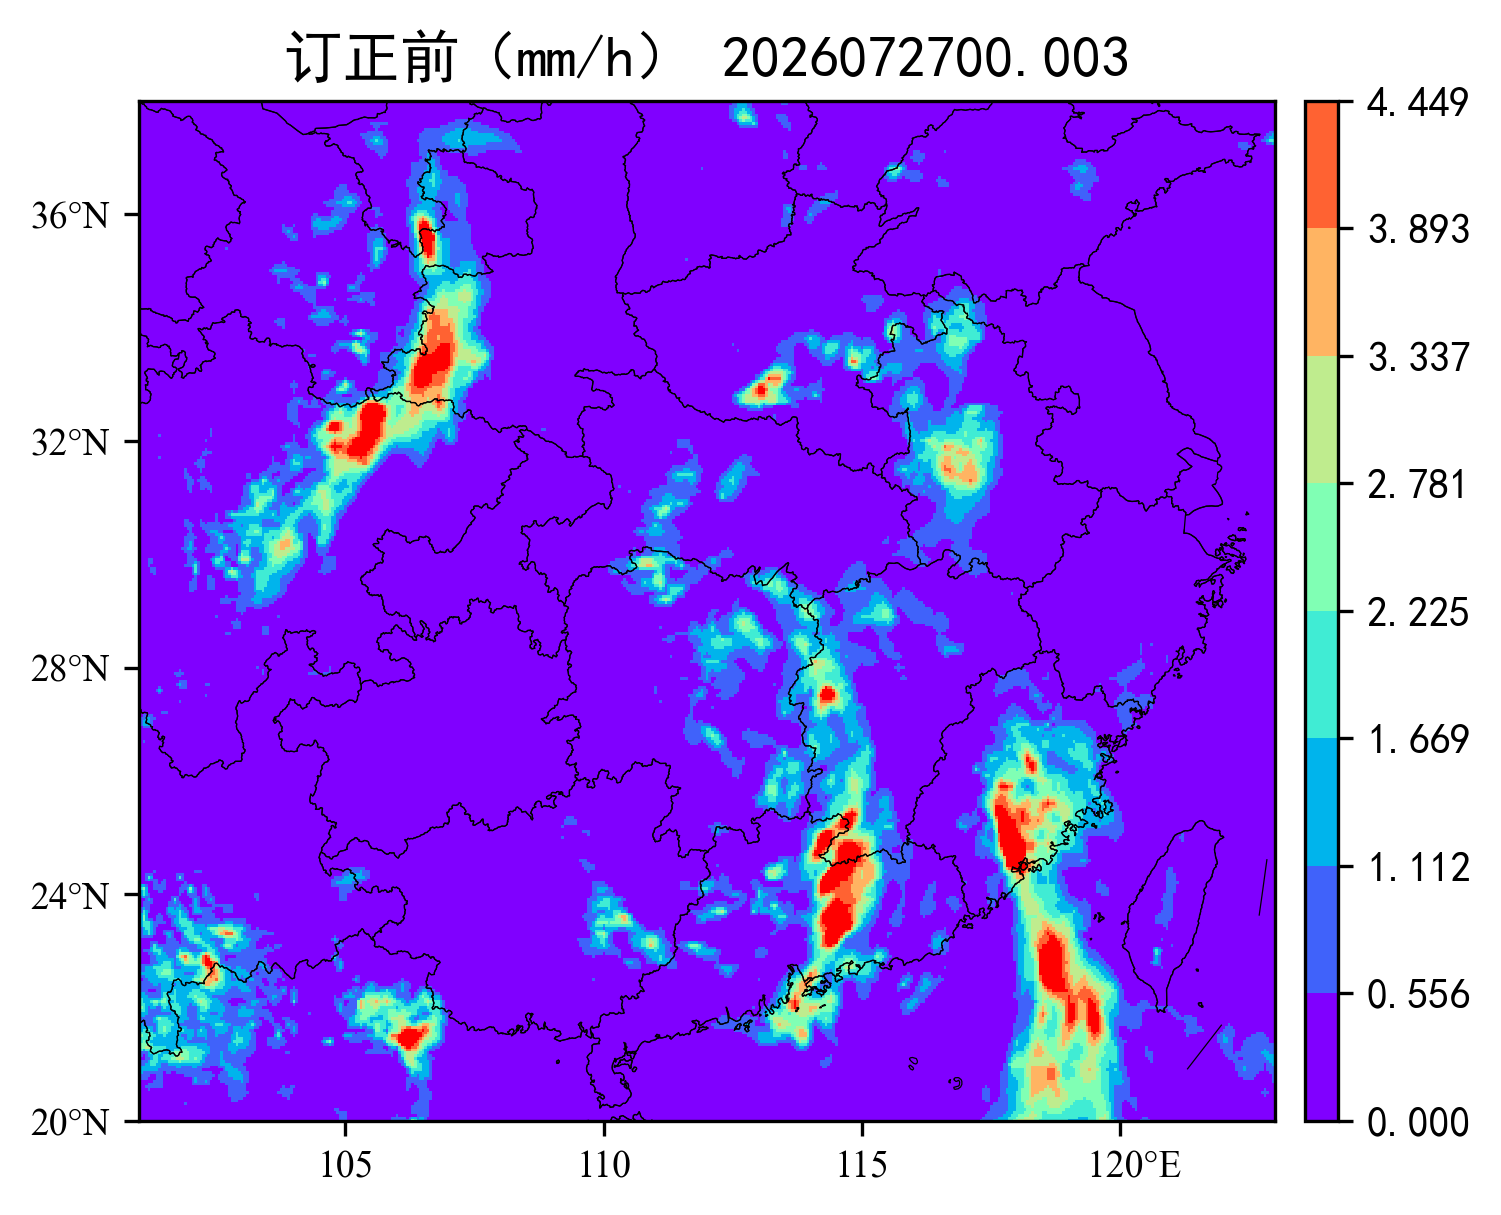

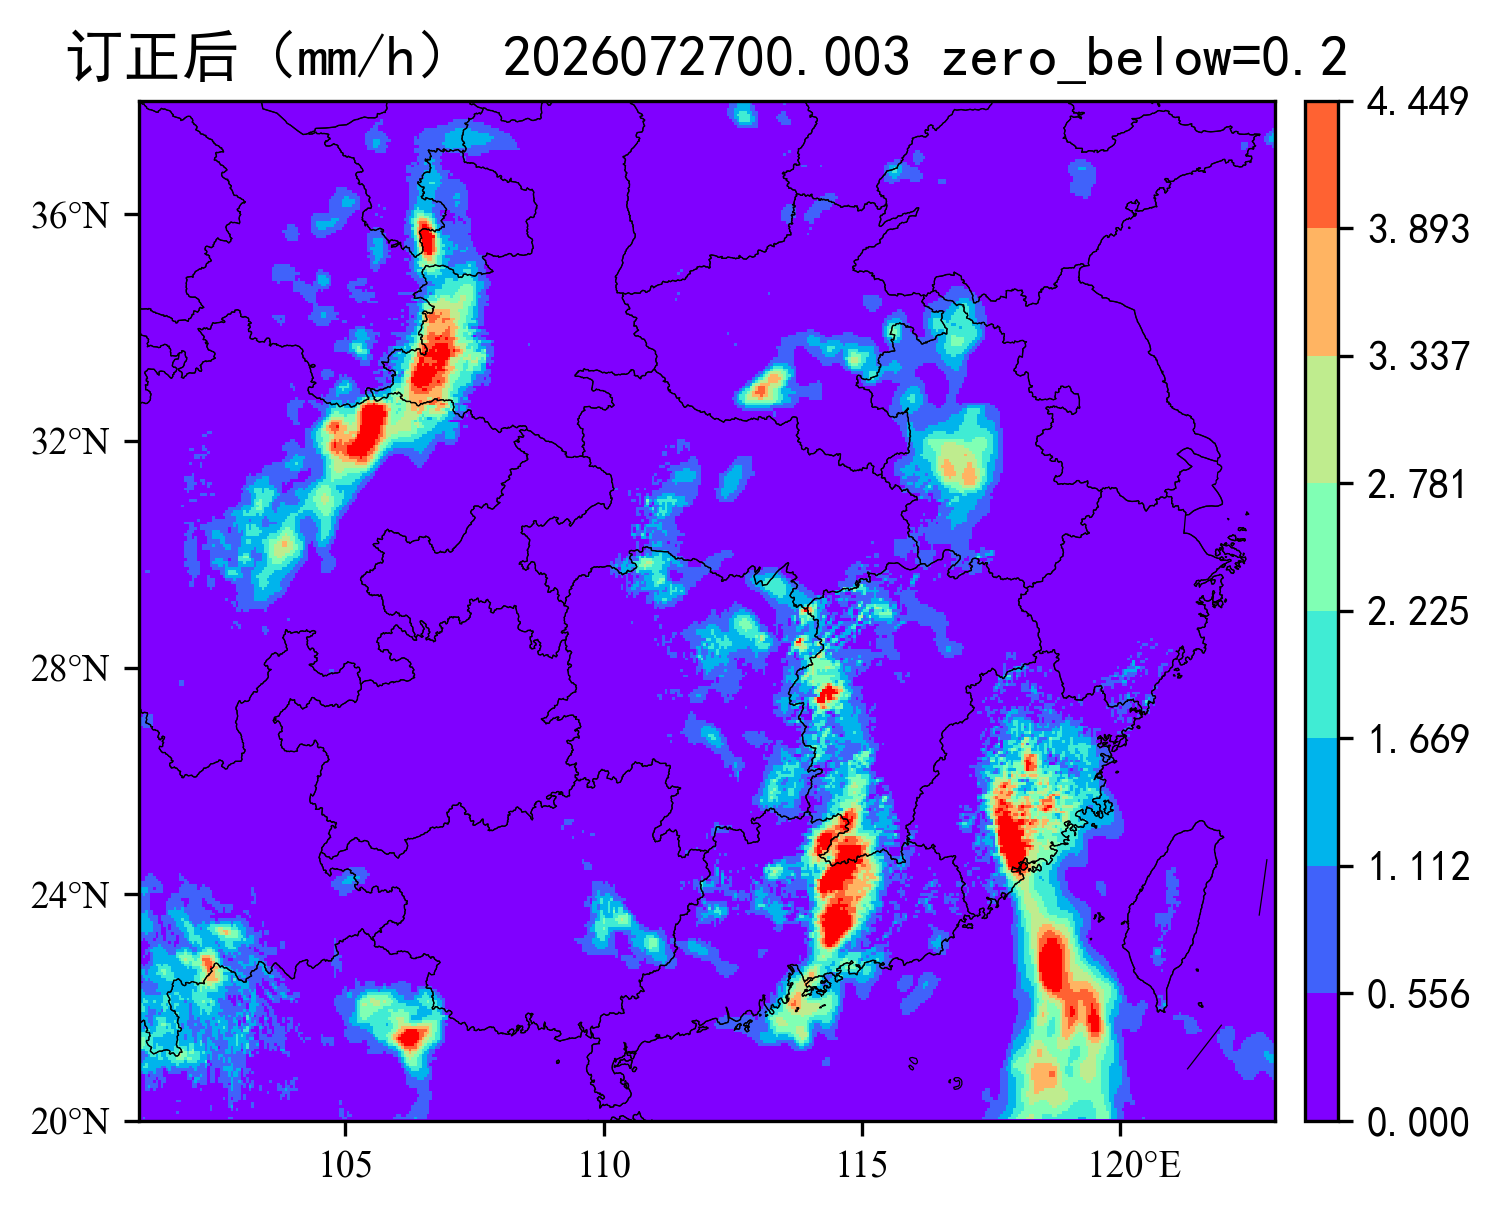

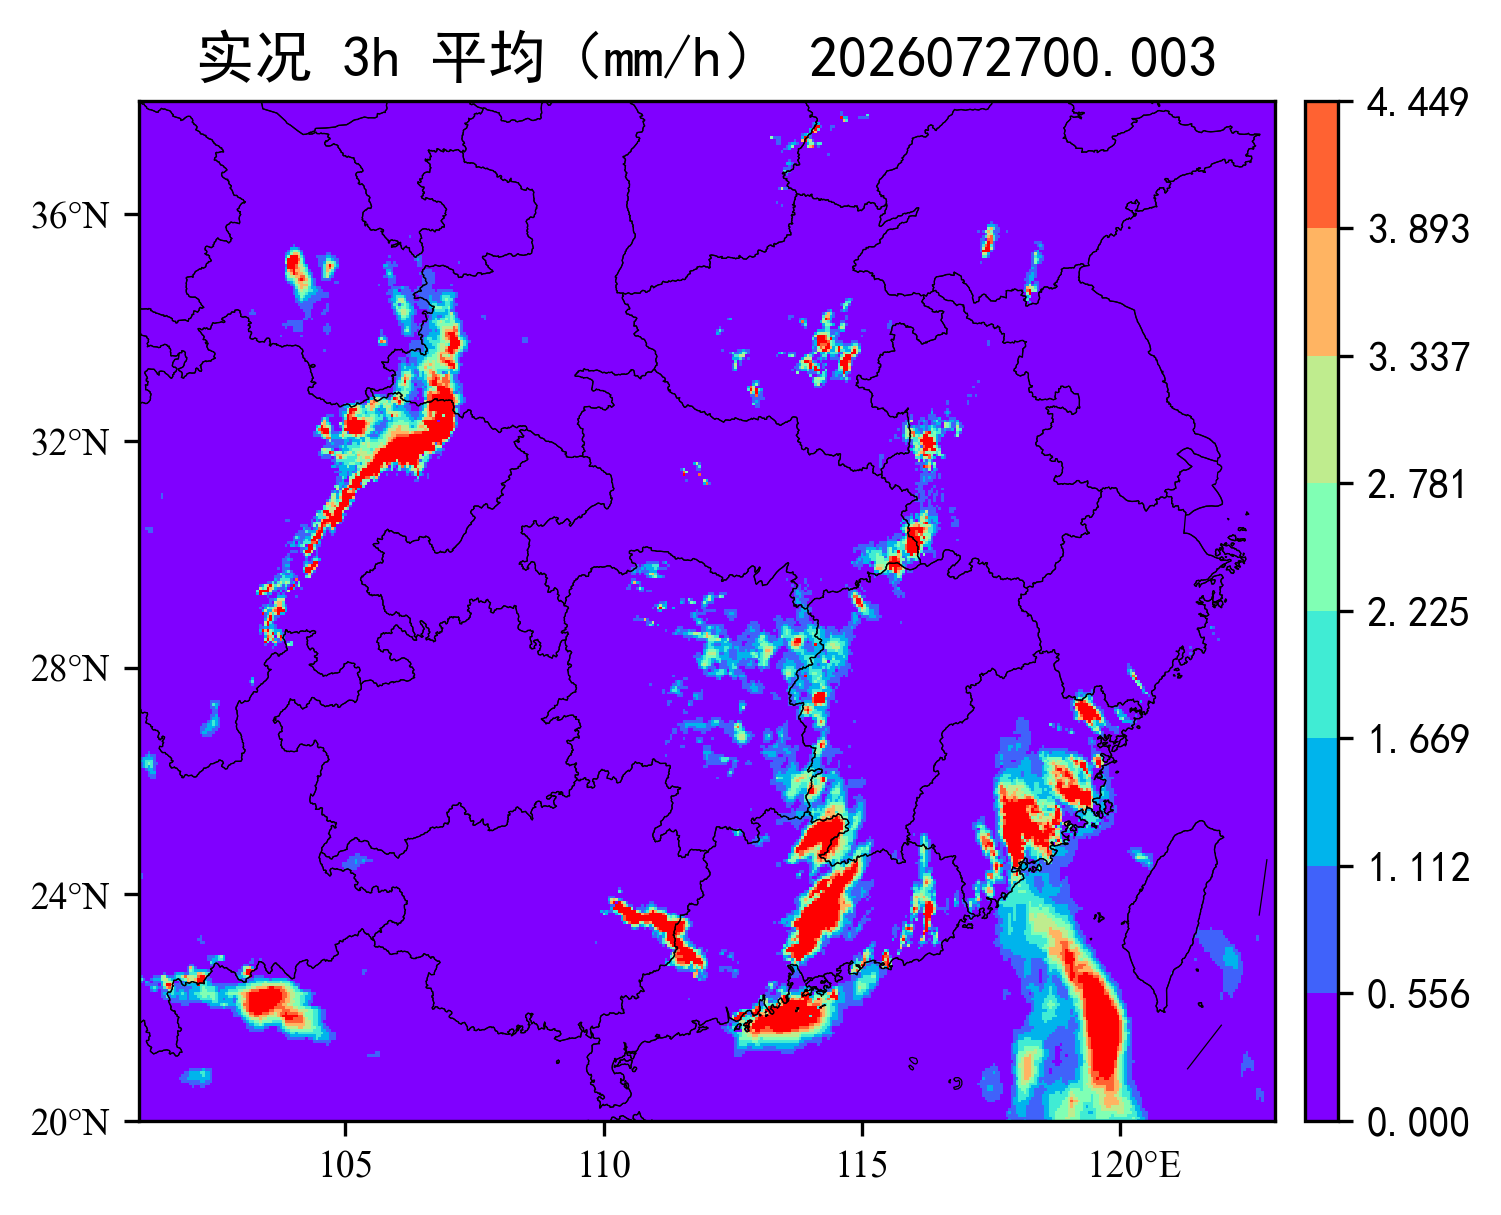

In [ ]:
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

FIG_DIR.mkdir(parents=True, exist_ok=True)
STEP = 5  # 1 km 绘图抽稀；设为 1 则不抽稀


def _thin(da, step=STEP):
    if step <= 1:
        return da
    return da.isel(lat=slice(None, None, step), lon=slice(None, None, step))


def _plottable(da):
    v = np.asarray(da.values, dtype=float)
    ok = np.isfinite(v) & (np.abs(v) < 1e10)
    if np.all(ok) or not np.any(ok):
        return da
    fill = float(np.min(v[ok]))
    return da.copy(data=np.where(ok, v, fill).astype(np.float32))


def _rain_clevs(*fields):
    vals = np.concatenate([np.asarray(da.values, dtype=float).ravel() for da in fields])
    vals = vals[np.isfinite(vals) & (vals >= 0) & (np.abs(vals) < 1e10)]
    if vals.size == 0:
        return [0, 0.1, 0.5, 1, 2, 5, 10]
    hi = float(np.nanpercentile(vals, 99))
    if hi <= 0:
        hi = float(np.nanmax(vals)) if np.nanmax(vals) > 0 else 1.0
    ticks = np.unique(np.round(np.linspace(0, hi, 9), 3))
    if ticks.size < 2:
        ticks = np.array([0.0, hi])
    return ticks.tolist()


def _show(da, title, filename, clevs):
    fig, ax = pcolormesh_2d_grid(
        _plottable(_thin(da)),
        title=title,
        clevs=clevs,
        save_path=str(FIG_DIR / filename),
    )
    print("saved", FIG_DIR / filename)
    return fig, ax


before = sample["before"]
after = sample["after"]
obs = sample["obs"]
tag = sample["tag"]
clevs = _rain_clevs(before, after, obs)


pcolormesh_2d_grid(
        _plottable(_thin(before)),
        title=f"订正前（mm/h） {tag}",
        clevs=clevs,
    )
pcolormesh_2d_grid(
        _plottable(_thin(after)),
        title=f"订正后（mm/h） {tag} zero_below={ZERO_BELOW:g}",
        clevs=clevs,
    )
pcolormesh_2d_grid(
        _plottable(_thin(obs)),
        title=f"实况 3h 平均（mm/h） {tag}",
        clevs=clevs,
    )